# 04 Field planning (layer 4)

Paddybird layer 4 decides **which field checks to make and which roads to drive** so that the
village calls from layer 3 (is the flooded paddy share above the 25% line?) are wrong as rarely as
possible for the field time available.

Reads `artifacts/layer1/` (units, roads), `artifacts/layer2/` (calibrated P(flooded paddy) per pixel
and per road segment) and `artifacts/layer3/` (tau, prior strength m, calibration prior pi_h, current
theta_u). Writes `artifacts/layer4/`: next-check ranking, day-1 routes, planned checks with their
inclusion probabilities, evaluation tables and figures, and `MANIFEST.json`.

Steps
1. Inputs: real layer 1 to 3 artifacts if present, otherwise a documented synthetic generator.
2. Allocation: next check = argmax expected drop in wrong calls (Gauss-Hermite look-ahead), against
   random, proportional and uncertainty-only baselines.
3. Flood-aware road graph and Dijkstra.
4. Orienteering (gain per extra minute) for K officers with a daily re-plan.
5. Randomised selection with known inclusion probabilities, and a check that it removes routing bias.
6. Held-out comparison of the planners: wrong calls against days, drive time and checks.
7. Day-1 plan for the input region, route figure, artifacts.

**No overfitting.** Every evaluation is a Monte Carlo over held-out scenarios with fixed seeds. The few
planner settings (pilot size, look-ahead batch, flood slow-down assumed by the planner, road-closure
cut-off, spine priority) are chosen on a separate set of
tuning seeds that never appear in the evaluation.

In [1]:
import json, hashlib, pathlib, time, copy, platform
import numpy as np
import scipy, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

from paddybird import allocation as A, routing as R, selection as Sel

ROOT = pathlib.Path.cwd()
if not (ROOT / "paddybird").exists():
    ROOT = ROOT / "notebooks"
ART = ROOT / "artifacts"
OUT = ART / "layer4"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 4
TUNE_REGIONS = list(range(100, 120))      # tuning scenarios (region seed; truth seed = region + 50000)
EVAL_REGIONS = list(range(1000, 1060))    # held-out evaluation scenarios, touched once
BIAS_REGIONS = list(range(2000, 2160))    # held-out scenarios for the bias check
TRUTH_OFFSET = 50000

# planning constants (from the report, section 3.5): 3 officers, 4 h day, 12 checks of 1.5 min per visit
K, T_DAY, C_VISIT, CHECK_MIN, SLOW, DAYS = 3, 240.0, 12, 1.5, 8.0, 5
U_ALLOC, U_ROUTE = 80, 30
BUDGETS = [0, 2, 4, 8, 12, 16, 24, 32]    # mean checks per village
SPINE_N, SPINE_FLOOR = 8.0, 0.05          # expected spine villages per campaign, minimum inclusion prob

# colours: categorical slots in fixed order (validated default palette), text stays neutral
COL = dict(random="#e87ba4", proportional="#eda100", uncertainty="#1baf7a", decision="#2a78d6",
           nearest="#e87ba4", gain_only="#eda100", gain_blind="#1baf7a", gain_aware="#2a78d6",
           gain_aware_spine="#eb6834")
INK, MUTED, GRID = "#1f1f1e", "#6b6a63", "#e4e3dd"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
                     "font.size": 9, "legend.frameon": False})
print("numpy", np.__version__, "scipy", scipy.__version__, "matplotlib", matplotlib.__version__, "python", platform.python_version())

numpy 2.4.6 scipy 1.17.1 matplotlib 3.11.2 python 3.11.9


## 1 Inputs

What the earlier layers provide today, and how this notebook uses it:
* **Layer 1** (real): the OpenStreetMap road graph of the study block (nodes, edges, dry minutes), the
  depot node and 36 grid units with their nearest road node. `R.load_region(ART)` reads these.
* **Layer 2**: calibrated maps exist only for the labelled Sen1Floods11 chips, not for the study block.
  So the flood layer over the block (road-segment flood probability, per-plot P) is drawn in
  `R.load_region` with the same documented recipe as the synthetic stand-in. The chip maps are used
  separately, with their hand labels, for a real-map-error check of the allocation rule (step 2b).
* **Layer 3**: tau and the prior strength m are read from `layer3/hyper.json`, so the estimator here is
  the same as layer 3's two-stratum form. pi_h is the mean P per map stratum (the flood layer is
  calibrated by construction).

If layer 1 is missing, everything falls back to `R.synthetic_region` (a 21 by 21 road lattice under a
smooth flood field, 30 villages; its docstring is the full specification). The Monte Carlo evaluation
always uses many synthetic regions so that results do not hinge on one map.

Field truth is never in the artifacts, so every evaluation simulates it. `R.draw_truth` draws one
held-out scenario: each village gets a map error b_u on the logit scale whose mean is zero but which is
larger behind flooded roads (so a roadside sample is biased), plots are flooded with probability
expit(logit P + b_u), and each road segment is flooded with its layer-2 probability.

In [2]:
hyp = ART / "layer3" / "hyper.json"
L3 = json.loads(hyp.read_text()) if hyp.exists() else {}
M_EST, TAU = float(L3.get("m", 5.0)), float(L3.get("tau", 0.25))
print("layer 3 estimator settings:", "read from layer3/hyper.json" if L3 else "defaults (layer 3 not written)", f"m = {M_EST:g}, tau = {TAU:g}")

def synth(reg_seed, U):
    return R.synthetic_region(reg_seed, U=U, m=M_EST, tau=TAU)

region = R.load_region(ART, seed=SEED)
if region is not None:
    INPUT_SOURCE = region["source"]
else:
    INPUT_SOURCE = "synthetic stand-in (layer 1 not written)"
    region = synth(SEED, U_ROUTE)
print("input:", INPUT_SOURCE)
U0 = len(region["P"])
N0 = np.array([len(p) for p in region["P"]])
print(f"villages {U0}, plots per village {N0.min()} to {N0.max()}, road nodes {len(region['xy'])}, segments {len(region['edges'])}")
print("tau", region["tau"], " m", region["m"], " pi_h (mapped dry, mapped flooded)", np.round(region["pi_h"], 3))
print("share of road segments with flood probability > 0.5:", round(float((region["p_edge"] > 0.5).mean()), 3))

layer 3 estimator settings: read from layer3/hyper.json m = 1, tau = 0.25


input: layer1 roads and units (Godavari delta block (Amalapuram, Konaseema, Andhra Pradesh)); flood layer semi-synthetic
villages 36, plots per village 2948 to 2950, road nodes 2096, segments 2567
tau 0.25  m 1.0  pi_h (mapped dry, mapped flooded) [0.157 0.722]
share of road segments with flood probability > 0.5: 0.18


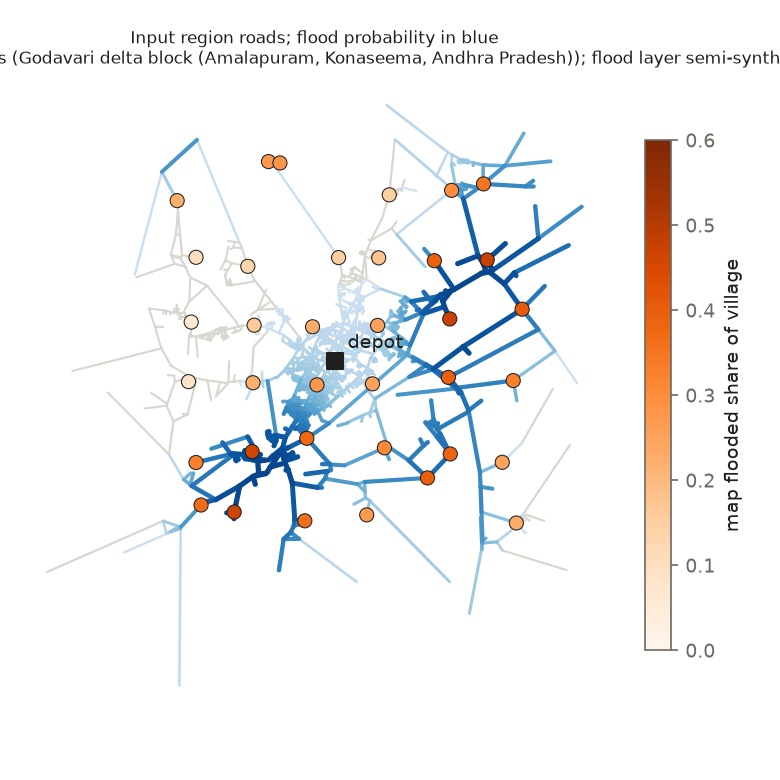

In [3]:
def draw_roads(ax, reg, flooded=None, lw=1.0):
    e, xy, p = reg["edges"], reg["xy"], reg["p_edge"] if flooded is None else flooded.astype(float)
    order = np.argsort(p)
    for j in order:
        a, b = e[j]
        wet = p[j]
        ax.plot(xy[[a, b], 0], xy[[a, b], 1], color=plt.cm.Blues(0.15 + 0.8 * wet) if wet > 0.05 else "#d7d6cf",
                lw=lw + 1.6 * wet, zorder=1, solid_capstyle="round")

fig, ax = plt.subplots(figsize=(5.2, 5.2))
draw_roads(ax, region)
uxy = region["xy"][region["unit_node"]]
share = np.array([p.mean() for p in region["P"]])
sc = ax.scatter(uxy[:, 0], uxy[:, 1], c=share, cmap="Oranges", vmin=0, vmax=0.6, s=46, edgecolor=INK, lw=0.5, zorder=3)
ax.scatter(*region["xy"][region["depot"]], marker="s", c=INK, s=60, zorder=4)
ax.annotate("depot", region["xy"][region["depot"]], xytext=(6, 6), textcoords="offset points", color=INK)
fig.colorbar(sc, ax=ax, shrink=0.7, label="map flooded share of village")
ax.set_title("Input region roads; flood probability in blue\n(" + INPUT_SOURCE + ")", color=INK, fontsize=8)
ax.set_aspect("equal"); ax.axis("off")
fig.tight_layout(); fig.savefig(OUT / "fig_region.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "fig_region.png")))

## 2 Allocation: where the next check goes

Layer 3's estimate for village u stratifies its plots by the map (mapped dry, mapped flooded) and
shrinks each stratum's checked rate toward the calibration prior pi_h with strength m. The chance that
the current call is wrong is Phi(-|theta_u - tau| / s_u). One more check in stratum h lowers the error to
s' and moves the estimate by a random amount of variance s_u^2 - s'^2; the **decision rule** sends the
next check to the (village, stratum) with the largest expected drop in that chance, with the expectation
taken by a 15-point Gauss-Hermite rule (`A.lookahead_gain`).

Baselines, all with the same estimator and the same number of checks:
* **random**: each check is a uniformly random plot of the whole region;
* **proportional**: checks split by village size and, inside a village, by stratum share;
* **uncertainty-only**: greedy largest drop in the village's variance (decision-blind).

This step has no travel cost (checks are free to place). Two settings, the pilot (checks per stratum
before the greedy phase) and the batch (checks placed per gain refresh), are tuned on the tuning seeds,
separately for the two greedy rules so the baseline gets the same care.

In [4]:
def alloc_trial(reg_seed, rule, pilot=1, batch=4, U=U_ALLOC, budgets=BUDGETS):
    reg = synth(reg_seed, U)
    tr = R.draw_truth(reg, reg_seed + TRUTH_OFFSET)
    above = np.array([y.mean() for y in tr["Y"]]) > reg["tau"]
    rng = np.random.default_rng(reg_seed + 7)
    wrong, bri = [], []
    if rule == "proportional":
        for b in budgets:
            S = A.StratSurvey(tr["Y"], reg["f"], reg["pi_h"], reg["m"], reg["tau"], np.random.default_rng(reg_seed + 7))
            call, P = A.proportional_allocation(S, b * U)
            wrong.append(A.wrong_rate(call, above)); bri.append(A.brier(P, above))
    else:
        S = A.StratSurvey(tr["Y"], reg["f"], reg["pi_h"], reg["m"], reg["tau"], rng)
        out = A.run_allocation(S, rule, [b * U for b in budgets], rng, pilot=pilot, batch=batch)
        for b in budgets:
            call, P = out[b * U]
            wrong.append(A.wrong_rate(call, above)); bri.append(A.brier(P, above))
    return np.array(wrong), np.array(bri)

# tuning (tuning seeds only): pick the setting with the lowest mean wrong-call rate over budgets 4 to 32
t0 = time.time()
tune_alloc = {}
for rule in ("uncertainty", "decision"):
    for pilot in (0, 1, 2):
        for batch in (1, 8):
            w = np.mean([alloc_trial(s, rule, pilot, batch)[0] for s in TUNE_REGIONS], 0)
            tune_alloc[f"{rule}|pilot={pilot}|batch={batch}"] = float(w[2:].mean())
best_alloc = {}
for rule in ("uncertainty", "decision"):
    k = min((k for k in tune_alloc if k.startswith(rule)), key=tune_alloc.get)
    best_alloc[rule] = dict(pilot=int(k.split("pilot=")[1].split("|")[0]), batch=int(k.split("batch=")[1]))
for k, v in tune_alloc.items():
    print(f"{k:32s} mean wrong {100 * v:5.2f}%")
print("chosen on tuning seeds:", best_alloc, f"({time.time() - t0:.0f} s)")

uncertainty|pilot=0|batch=1      mean wrong 13.14%
uncertainty|pilot=0|batch=8      mean wrong 13.14%
uncertainty|pilot=1|batch=1      mean wrong 13.20%
uncertainty|pilot=1|batch=8      mean wrong 13.26%
uncertainty|pilot=2|batch=1      mean wrong 14.02%
uncertainty|pilot=2|batch=8      mean wrong 14.04%
decision|pilot=0|batch=1         mean wrong 10.02%
decision|pilot=0|batch=8         mean wrong 10.18%
decision|pilot=1|batch=1         mean wrong 10.33%
decision|pilot=1|batch=8         mean wrong 10.70%
decision|pilot=2|batch=1         mean wrong 11.23%
decision|pilot=2|batch=8         mean wrong 11.46%
chosen on tuning seeds: {'uncertainty': {'pilot': 0, 'batch': 1}, 'decision': {'pilot': 0, 'batch': 1}} (145 s)


In [5]:
# HELD-OUT EVALUATION (allocation): evaluation seeds, touched once with the settings fixed above
t0 = time.time()
ev_alloc = {}
for rule in A.RULES:
    kw = best_alloc.get(rule, {})
    rows = [alloc_trial(s, rule, **kw) for s in EVAL_REGIONS]
    ev_alloc[rule] = dict(wrong=np.array([r[0] for r in rows]), brier=np.array([r[1] for r in rows]))
print(f"{len(EVAL_REGIONS)} held-out scenarios x {U_ALLOC} villages ({time.time() - t0:.0f} s)")

def band(x):
    x = np.asarray(x, float)
    m, se = x.mean(0), x.std(0, ddof=1) / np.sqrt(len(x))
    return m, m - 1.96 * se, m + 1.96 * se

print("wrong 25% calls (%) by mean checks per village:", BUDGETS)
for rule in A.RULES:
    m, lo, hi = band(ev_alloc[rule]["wrong"])
    print(f"{rule:13s}", " ".join(f"{100 * x:5.1f}" for x in m))
# paired differences, decision minus each baseline (same scenarios)
pair_alloc = {}
for base in ("random", "proportional", "uncertainty"):
    d = ev_alloc["decision"]["wrong"] - ev_alloc[base]["wrong"]
    m, lo, hi = band(d)
    pair_alloc[base] = dict(mean=m.tolist(), lo=lo.tolist(), hi=hi.tolist())
    print(f"decision - {base:12s}", " ".join(f"{100 * x:+5.1f}[{100 * a:+.1f},{100 * b:+.1f}]" for x, a, b in zip(m, lo, hi)))

60 held-out scenarios x 80 villages (136 s)
wrong 25% calls (%) by mean checks per village: [0, 2, 4, 8, 12, 16, 24, 32]
random         11.4  20.4  21.1  18.0  15.5  14.0  11.8  10.0
proportional   11.4  22.5  21.7  18.3  15.1  13.8  11.5   9.8
uncertainty    11.4  23.5  18.0  15.8  14.0  12.6  11.1  10.4
decision       11.4  19.2  14.7  11.8   9.8   8.6   7.5   7.3
decision - random        +0.0[+0.0,+0.0]  -1.2[-2.1,-0.3]  -6.5[-7.5,-5.4]  -6.2[-7.1,-5.4]  -5.7[-6.7,-4.7]  -5.4[-6.4,-4.5]  -4.2[-5.0,-3.5]  -2.8[-3.5,-2.1]
decision - proportional  +0.0[+0.0,+0.0]  -3.3[-4.1,-2.5]  -7.1[-8.1,-6.1]  -6.5[-7.4,-5.6]  -5.3[-6.1,-4.4]  -5.2[-6.1,-4.3]  -4.0[-4.8,-3.2]  -2.5[-3.1,-1.9]
decision - uncertainty   +0.0[+0.0,+0.0]  -4.4[-5.4,-3.3]  -3.3[-4.0,-2.6]  -4.0[-4.8,-3.2]  -4.2[-5.1,-3.2]  -4.0[-4.7,-3.2]  -3.6[-4.3,-2.8]  -3.1[-3.7,-2.5]


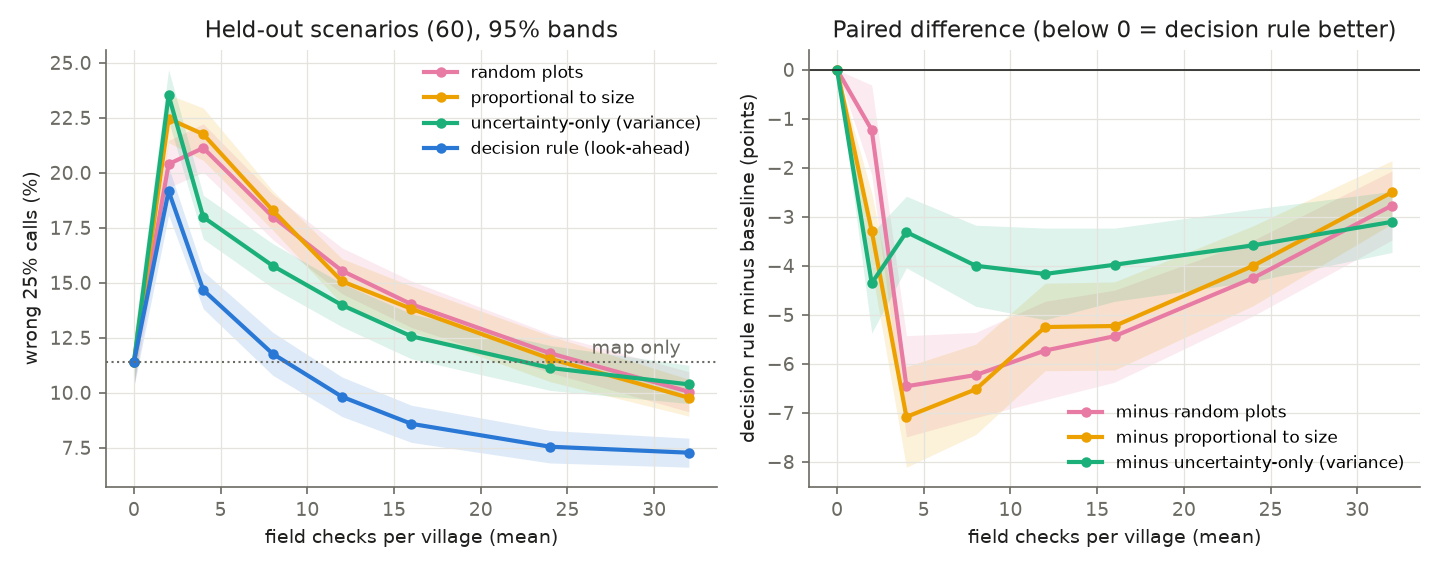

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8))
lab = dict(random="random plots", proportional="proportional to size", uncertainty="uncertainty-only (variance)",
           decision="decision rule (look-ahead)")
for rule in A.RULES:
    m, lo, hi = band(ev_alloc[rule]["wrong"])
    axs[0].plot(BUDGETS, 100 * m, marker="o", ms=4, color=COL[rule], label=lab[rule])
    axs[0].fill_between(BUDGETS, 100 * lo, 100 * hi, color=COL[rule], alpha=0.15, lw=0)
axs[0].axhline(100 * ev_alloc["decision"]["wrong"][:, 0].mean(), color=MUTED, lw=1, ls=":")
axs[0].annotate("map only", (BUDGETS[-1], 100 * ev_alloc["decision"]["wrong"][:, 0].mean()), xytext=(-4, 4),
                textcoords="offset points", ha="right", color=MUTED)
axs[0].set_xlabel("field checks per village (mean)"); axs[0].set_ylabel("wrong 25% calls (%)")
axs[0].set_title(f"Held-out scenarios ({len(EVAL_REGIONS)}), 95% bands", color=INK); axs[0].legend(fontsize=8)
for base in ("random", "proportional", "uncertainty"):
    p = pair_alloc[base]
    axs[1].plot(BUDGETS, 100 * np.array(p["mean"]), marker="o", ms=4, color=COL[base], label=f"minus {lab[base]}")
    axs[1].fill_between(BUDGETS, 100 * np.array(p["lo"]), 100 * np.array(p["hi"]), color=COL[base], alpha=0.15, lw=0)
axs[1].axhline(0, color=INK, lw=0.8)
axs[1].set_xlabel("field checks per village (mean)"); axs[1].set_ylabel("decision rule minus baseline (points)")
axs[1].set_title("Paired difference (below 0 = decision rule better)", color=INK); axs[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "fig_wrong_vs_checks.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "fig_wrong_vs_checks.png")))

## 2b Real map error: labelled chips

The synthetic map error above is our own assumption. Layer 1 cuts the labelled Sen1Floods11 chips into
pseudo-villages (4 per chip) and layer 2 gives each pixel a calibrated P(flooded). Here a plot is a
pixel with a hand label, the truth is the label, and the 25% call is on the labelled flooded share. The
calibration prior pi_h is fitted on the **train** events only; the comparison runs on the **test**
events (Bolivia, India), held out by event in layers 1 and 2, with the allocation settings already
fixed on the synthetic tuning seeds (nothing is tuned here). Monte Carlo seeds only change which plots
are drawn. Caveat: the labels are water, not flooded paddy.

train units 316 -> pi_h = [0.025 0.677]; test units 91, 18% truly above 25%


TEST events, wrong 25% calls (%) by mean checks per unit: [0, 2, 4, 8, 16, 32]
random          8.8  10.3   9.4   6.6   4.7   3.7
proportional    8.8  10.5   8.4   6.2   5.1   3.4
uncertainty     8.8   7.1   6.2   4.9   4.3   3.1
decision        8.8   6.6   5.8   4.1   3.6   3.6
decision - random        +0.0[+0.0,+0.0]  -3.7[-4.3,-3.0]  -3.6[-4.3,-2.9]  -2.6[-3.2,-2.0]  -1.1[-1.6,-0.6]  -0.1[-0.5,+0.3]
decision - proportional  +0.0[+0.0,+0.0]  -3.9[-4.5,-3.3]  -2.7[-3.3,-2.0]  -2.1[-2.6,-1.6]  -1.4[-1.9,-1.0]  +0.3[-0.1,+0.6]
decision - uncertainty   +0.0[+0.0,+0.0]  -0.5[-0.9,-0.2]  -0.4[-0.9,+0.0]  -0.8[-1.2,-0.5]  -0.6[-1.1,-0.2]  +0.5[+0.1,+0.9]


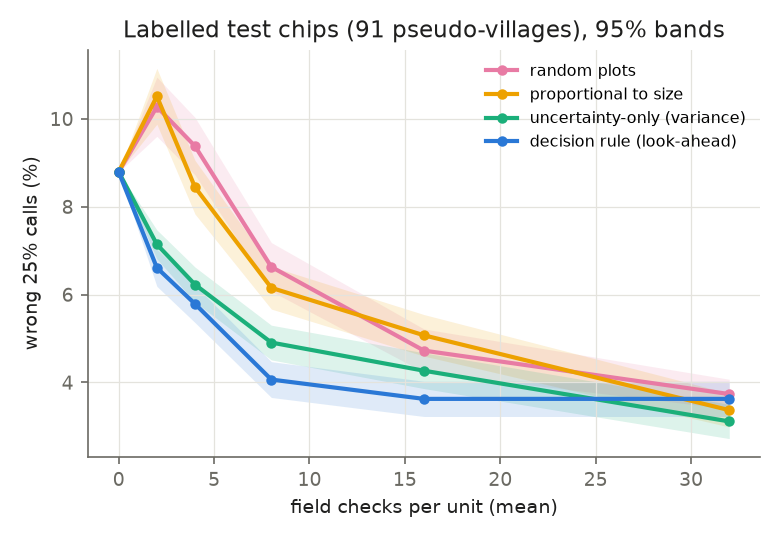

In [7]:
chips_train = A.load_chip_units(ART, "train")
chips_test = A.load_chip_units(ART, "test")
real_alloc = None
if chips_train is not None and chips_test is not None:
    Ytr, ftr = np.concatenate(chips_train["Y"]), np.concatenate(chips_train["f"])
    pi_chip = np.array([Ytr[~ftr].mean(), Ytr[ftr].mean()])
    above_c = np.array([y.mean() for y in chips_test["Y"]]) > TAU
    Uc = len(chips_test["Y"])
    print(f"train units {len(chips_train['Y'])} -> pi_h = {np.round(pi_chip, 3)}; test units {Uc}, {100 * above_c.mean():.0f}% truly above 25%")
    CHIP_BUDGETS = [0, 2, 4, 8, 16, 32]
    real_alloc = {}
    for rule in A.RULES:
        W = []
        for s in EVAL_REGIONS:
            rng = np.random.default_rng(s)
            if rule == "proportional":
                w = [A.wrong_rate(A.proportional_allocation(A.StratSurvey(chips_test["Y"], chips_test["f"], pi_chip, M_EST, TAU,
                                                                          np.random.default_rng(s)), b * Uc)[0], above_c) for b in CHIP_BUDGETS]
            else:
                S = A.StratSurvey(chips_test["Y"], chips_test["f"], pi_chip, M_EST, TAU, rng)
                out = A.run_allocation(S, rule, [b * Uc for b in CHIP_BUDGETS], rng, **best_alloc.get(rule, {}))
                w = [A.wrong_rate(out[b * Uc][0], above_c) for b in CHIP_BUDGETS]
            W.append(w)
        real_alloc[rule] = np.array(W)
    print("TEST events, wrong 25% calls (%) by mean checks per unit:", CHIP_BUDGETS)
    for rule in A.RULES:
        m, lo, hi = band(real_alloc[rule])
        print(f"{rule:13s}", " ".join(f"{100 * x:5.1f}" for x in m))
    real_pair = {}
    for base in ("random", "proportional", "uncertainty"):
        m, lo, hi = band(real_alloc["decision"] - real_alloc[base])
        real_pair[base] = dict(mean=m.tolist(), lo=lo.tolist(), hi=hi.tolist())
        print(f"decision - {base:12s}", " ".join(f"{100 * x:+5.1f}[{100 * a:+.1f},{100 * b:+.1f}]" for x, a, b in zip(m, lo, hi)))
    fig, ax = plt.subplots(figsize=(5.2, 3.6))
    for rule in A.RULES:
        m, lo, hi = band(real_alloc[rule])
        ax.plot(CHIP_BUDGETS, 100 * m, marker="o", ms=4, color=COL[rule], label=lab[rule])
        ax.fill_between(CHIP_BUDGETS, 100 * lo, 100 * hi, color=COL[rule], alpha=0.15, lw=0)
    ax.set_xlabel("field checks per unit (mean)"); ax.set_ylabel("wrong 25% calls (%)")
    ax.set_title(f"Labelled test chips ({Uc} pseudo-villages), 95% bands", color=INK); ax.legend(fontsize=7.5)
    fig.tight_layout(); fig.savefig(OUT / "fig_wrong_vs_checks_real_chips.png", dpi=150); plt.close(fig)
    display(Image(str(OUT / "fig_wrong_vs_checks_real_chips.png")))
else:
    print("labelled chip units or layer 2 maps not present; real-error check skipped")

## 3 Flood-aware road graph

The road graph carries each segment's dry travel time and its layer-2 flood probability. The
**flood-blind** cost is the dry time. The **flood-aware** cost slows a segment by its flood
probability, base * (1 + (s_plan - 1) * p_flood), and removes ("closes") segments with p_flood above a
cut-off. Shortest paths come from Dijkstra (`scipy.sparse.csgraph.dijkstra`) between the depot and
every village. In the simulated truth a flooded segment takes 8 times its dry time (report, section
3.5).

s_plan is not simply 8. The expected time of each segment, summed along the expected-cost path, over-
states the true shortest time, because on the day the officer takes whichever roads happen to be dry
(the minimum over paths is below the path of minimum expected cost). So s_plan is fitted on the tuning
seeds by the mean absolute relative error of depot-to-village times, then checked on held-out
scenarios against the dry map and against the unfitted s_plan = 8.

In [8]:
def travel_error(reg_seed, s_plan):
    reg = synth(reg_seed, U_ROUTE)
    tr = R.draw_truth(reg, reg_seed + TRUTH_OFFSET)
    Dt, _, _ = R.shortest(reg, R.edge_costs(reg, "true", SLOW, flooded_edge=tr["flooded_edge"]))
    w = R.edge_costs(reg, "blind") if s_plan is None else R.edge_costs(reg, "aware", s_plan)
    D, _, _ = R.shortest(reg, w)
    rel = (D[0, 1:] - Dt[0, 1:]) / Dt[0, 1:]
    rel = rel[np.isfinite(rel)]
    return float(np.abs(rel).mean()), float(rel.mean())

S_GRID = (1.5, 2.0, 3.0, 4.0, 6.0, 8.0)
tune_slow = {s: float(np.mean([travel_error(r, s)[0] for r in TUNE_REGIONS])) for s in S_GRID}
PLAN_SLOW = min(tune_slow, key=tune_slow.get)
print("tuning seeds, mean |relative error|:", {k: round(v, 3) for k, v in tune_slow.items()}, "-> s_plan =", PLAN_SLOW)

te = {}
for name, s in (("dry road map", None), ("flood-aware, s_plan = 8", 8.0), (f"flood-aware, s_plan = {PLAN_SLOW:g} (fitted)", PLAN_SLOW)):
    rows = np.array([travel_error(r, s) for r in EVAL_REGIONS])
    te[name] = dict(abs=float(rows[:, 0].mean()), signed=float(rows[:, 1].mean()),
                    abs_lo=float(band(rows[:, 0])[1]), abs_hi=float(band(rows[:, 0])[2]))
    print(f"held-out {name:32s} mean |rel error| {100 * te[name]['abs']:5.1f}% [{100 * te[name]['abs_lo']:.1f}, {100 * te[name]['abs_hi']:.1f}]  signed {100 * te[name]['signed']:+5.1f}%")

tuning seeds, mean |relative error|: {1.5: 0.296, 2.0: 0.268, 3.0: 0.226, 4.0: 0.215, 6.0: 0.314, 8.0: 0.517} -> s_plan = 4.0


held-out dry road map                     mean |rel error|  29.5% [24.4, 34.7]  signed -29.5%


held-out flood-aware, s_plan = 8          mean |rel error|  52.1% [44.5, 59.6]  signed +51.5%


held-out flood-aware, s_plan = 4 (fitted) mean |rel error|  21.0% [18.4, 23.5]  signed  +7.4%


## 4 Orienteering for K officers with a daily re-plan

Each morning the planner recomputes, for every village, the expected drop in P(wrong call) from a
visit of 12 checks (`A.visit_gain`, same Gauss-Hermite look-ahead), then repeatedly inserts the village
with the highest **gain per extra minute** (extra drive plus 18 minutes of checks) into the cheapest
position of any of the K = 3 officers' routes that still fits in a 4-hour day (`R.insertion`). Officers
then drive the true flooded roads and turn back when the next stop no longer fits (`R.execute`).

Planners compared (every village is answered every day; only the visits differ):
* **nearest**: nearest unvisited village on the dry road map (the usual practice);
* **gain_only**: highest gain first, travel ignored when choosing;
* **gain_blind**: gain per minute, planned on the dry road map;
* **gain_aware**: gain per minute, planned on the flood-aware graph;
* **gain_aware_spine**: gain_aware plus a randomised spine of villages with known inclusion
  probabilities (step 5), which are visited first.

Tuned on tuning seeds: the closure cut-off p_close (by the wrong-call rate after the last day).

In [9]:
def campaign(reg_seed, planner, p_close=None, days=DAYS, rep=0, priority="size", keep=False, reg=None):
    reg = synth(reg_seed, U_ROUTE) if reg is None else reg
    tr = R.draw_truth(reg, reg_seed + TRUTH_OFFSET)
    rec = R.run_campaign(reg, tr, planner, np.random.default_rng(reg_seed + 11 + 1000 * rep), days=days, K=K,
                         t_day=T_DAY, C=C_VISIT, check_min=CHECK_MIN, slow=SLOW, p_close=p_close,
                         plan_slow=PLAN_SLOW, spine_n=SPINE_N, spine_floor=SPINE_FLOOR,
                         frame_margin=FRAME_MARGIN, spine_priority=priority, keep_survey=keep)
    return (rec, reg, tr) if keep else rec

FRAME_MARGIN = 0.6
t0 = time.time()
tune_close = {}
for pc in (None, 0.9, 0.7, 0.5):
    tune_close[str(pc)] = float(np.mean([campaign(s, "gain_aware", pc)["wrong"][-1] for s in TUNE_REGIONS]))
    print(f"p_close={str(pc):5s} tuning wrong after day {DAYS}: {100 * tune_close[str(pc)]:.2f}%")
P_CLOSE = min(tune_close, key=tune_close.get)
P_CLOSE = None if P_CLOSE == "None" else float(P_CLOSE)
print("chosen p_close:", P_CLOSE, f"({time.time() - t0:.0f} s)")

p_close=None  tuning wrong after day 5: 7.33%


p_close=0.9   tuning wrong after day 5: 7.83%


p_close=0.7   tuning wrong after day 5: 7.17%


p_close=0.5   tuning wrong after day 5: 8.50%
chosen p_close: 0.7 (17 s)


## 5 Randomised selection with known inclusion probabilities

Routes favour villages near the depot and on dry roads, so the checks they collect are not a random
sample of the region. Village calls are not hurt by this (inside a village the plots are still drawn at
random per stratum), but anything pooled across villages is: the map-calibration rate pi_h and the
district flooded share.

The fix is a probability **spine** (`paddybird.selection`):
* **Frame.** Villages whose expected round trip plus checks on the flood-aware graph fits in 60% of a
  day. Villages outside the frame cannot be drawn; pooled design estimates are for the frame, and the
  frame's share of plots is reported (a coverage gap, not something weighting can fix).
* **Draw.** Before day 1 each frame village v is drawn independently (Poisson sampling) with
  q_v = clip(c * priority_v, 0.05, 1), c set so that 8 villages are expected.
* **Visit.** Drawn villages are mandatory stops (inserted first, carried to the next day if not reached),
  and their first visit checks 6 plots per map stratum by simple random sampling. A checked plot then
  has the known inclusion probability q_v * c_vh / N_vh, which is written with the check for layer 3.
* **Estimate.** Hajek (weights 1 / q_v, ratio to the estimated frame size) and Horvitz-Thompson (the
  frame size per stratum is known from the map, so only the numerator is estimated).

The priority is a design choice, picked on tuning seeds by the root-mean-square error of the Hajek
estimates: the visit gain (what the report used), village size (classic probability proportional to
size), or size times the square root of the gain.

In [10]:
def spine_estimates(reg_seed, rep=0, priority="size"):
    rec, reg, tr = campaign(reg_seed, "gain_aware_spine", P_CLOSE, rep=rep, priority=priority, keep=True)
    S, sp = rec["survey"], rec["spine"]
    fr = sp["frame"]
    if not fr.any():
        return None
    Yf = np.concatenate([tr["Y"][u] for u in np.flatnonzero(fr)]); ff = np.concatenate([reg["f"][u] for u in np.flatnonzero(fr)])
    true_pi, true_share = np.array([Yf[~ff].mean(), Yf[ff].mean()]), Yf.mean()
    got = [v for v in sp["drawn"] if v not in sp["unreached"]]
    dk, dn, q = sp["design"]["k"], sp["design"]["n"], sp["q"]
    visited = np.flatnonzero(S.n.sum(1) > 0)
    one = np.ones(S.U)
    Pf = np.concatenate([reg["P"][u] for u in np.flatnonzero(fr)])
    out = dict(
        hajek=np.r_[Sel.hajek_rate(dk, dn, S.Nh, q, got), Sel.hajek_share(dk, dn, S.Nh, q, got)],
        ht=np.r_[Sel.ht_rate(dk, dn, S.Nh, q, got, fr), Sel.ht_share(dk, dn, S.Nh, q, got, fr)],
        spine_unweighted=np.r_[Sel.hajek_rate(dk, dn, S.Nh, one, got), Sel.hajek_share(dk, dn, S.Nh, one, got)],
        naive_routed=np.r_[Sel.naive_rate(S.k, S.n), Sel.naive_share(S.k, S.n, S.Nh, visited)],
        map_only=np.r_[reg["pi_h"], Pf.mean()])
    truth = np.r_[true_pi, true_share]
    return dict(err={k: v - truth for k, v in out.items()}, drawn=len(sp["drawn"]), got=len(got),
                coverage=float(S.N[fr].sum() / S.N.sum()))

def summarise(trials, ests):
    tab = {}
    for est in ests:
        x = np.array([t["err"][est] for t in trials], float)
        for j, tgt in enumerate(("pi_dry", "pi_flooded", "district_share")):
            xj = x[:, j][np.isfinite(x[:, j])]
            m, lo, hi = band(xj)
            tab[f"{est}|{tgt}"] = dict(bias=float(m), lo=float(lo), hi=float(hi), rmse=float(np.sqrt((xj ** 2).mean())), n=int(len(xj)))
    return tab

t0 = time.time()
tune_prio = {}
for pr in R.SPINE_PRIORITIES:
    tr_ = [t for s in TUNE_REGIONS for rep in range(3) if (t := spine_estimates(s, rep, pr)) is not None]
    tab = summarise(tr_, ["hajek"])
    tune_prio[pr] = float(np.mean([tab[f"hajek|{t}"]["rmse"] for t in ("pi_dry", "pi_flooded", "district_share")]))
    print(f"priority {pr:17s} tuning mean RMSE of Hajek estimates {tune_prio[pr]:.4f}")
SPINE_PRIORITY = min(tune_prio, key=tune_prio.get)
print("chosen spine priority:", SPINE_PRIORITY, f"({time.time() - t0:.0f} s)")

priority gain              tuning mean RMSE of Hajek estimates 0.0667


priority size              tuning mean RMSE of Hajek estimates 0.0642


priority size_x_sqrt_gain  tuning mean RMSE of Hajek estimates 0.0668
chosen spine priority: size (36 s)


In [11]:
# HELD-OUT EVALUATION (bias check): bias seeds, settings fixed above
t0 = time.time()
bt = [t for s in BIAS_REGIONS if (t := spine_estimates(s, 0, SPINE_PRIORITY)) is not None]
EST = ("hajek", "ht", "spine_unweighted", "naive_routed", "map_only")
bias_tab = summarise(bt, EST)
print(f"{len(bt)} held-out scenarios ({time.time() - t0:.0f} s); spine drawn {np.mean([b['drawn'] for b in bt]):.1f}, "
      f"reached {np.mean([b['got'] for b in bt]):.2f}; frame covers {100 * np.mean([b['coverage'] for b in bt]):.0f}% of plots")
print(f"{'estimator | target (frame)':34s} {'bias':>8s} {'95% CI':>20s} {'rmse':>7s}")
for k, v in bias_tab.items():
    print(f"{k:34s} {v['bias']:+8.4f} [{v['lo']:+.4f}, {v['hi']:+.4f}] {v['rmse']:7.4f}")

118 held-out scenarios (27 s); spine drawn 7.7, reached 7.68; frame covers 51% of plots
estimator | target (frame)             bias               95% CI    rmse
hajek|pi_dry                        -0.0001 [-0.0090, +0.0088]  0.0492
hajek|pi_flooded                    -0.0022 [-0.0162, +0.0118]  0.0772
hajek|district_share                -0.0002 [-0.0088, +0.0083]  0.0472
ht|pi_dry                           -0.0021 [-0.0122, +0.0079]  0.0556
ht|pi_flooded                       -0.0088 [-0.0457, +0.0281]  0.2037
ht|district_share                   -0.0029 [-0.0151, +0.0092]  0.0672
spine_unweighted|pi_dry             +0.0003 [-0.0090, +0.0095]  0.0509
spine_unweighted|pi_flooded         -0.0030 [-0.0172, +0.0112]  0.0785
spine_unweighted|district_share     -0.0001 [-0.0087, +0.0085]  0.0475
naive_routed|pi_dry                 +0.0154 [+0.0107, +0.0201]  0.0300
naive_routed|pi_flooded             -0.0052 [-0.0138, +0.0035]  0.0479
naive_routed|district_share         +0.0032 [-0.0042, +0.0

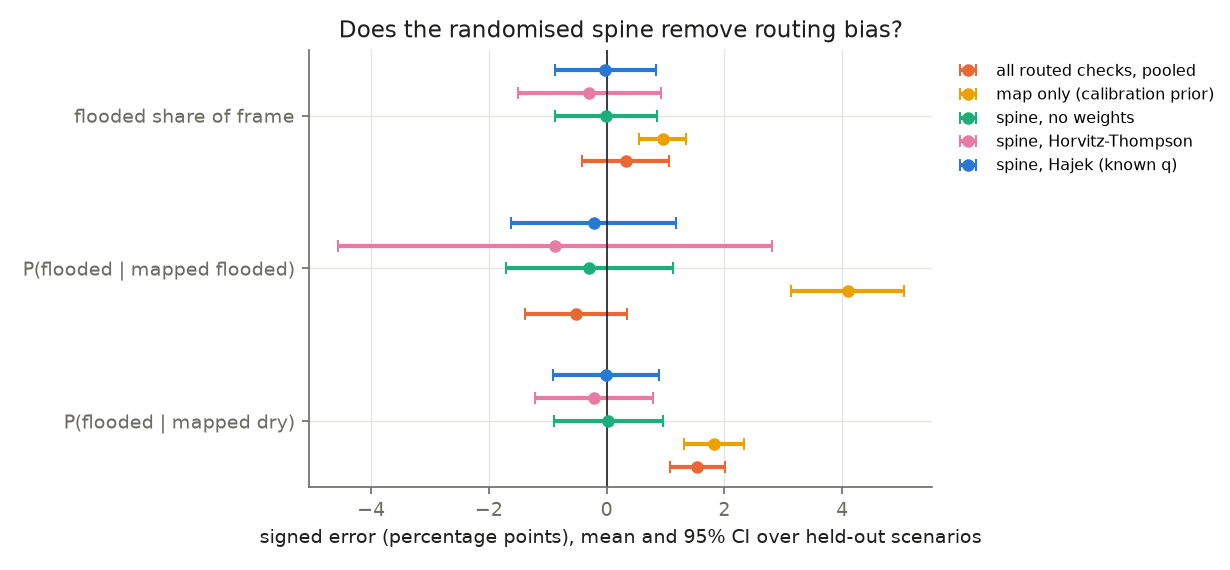

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 3.8))
tg = ["pi_dry", "pi_flooded", "district_share"]
names = dict(naive_routed="all routed checks, pooled", map_only="map only (calibration prior)",
             spine_unweighted="spine, no weights", ht="spine, Horvitz-Thompson", hajek="spine, Hajek (known q)")
cols = dict(naive_routed="#eb6834", map_only="#eda100", spine_unweighted="#1baf7a", ht="#e87ba4", hajek="#2a78d6")
order = ("naive_routed", "map_only", "spine_unweighted", "ht", "hajek")
for i, est in enumerate(order):
    for j, t in enumerate(tg):
        v = bias_tab[f"{est}|{t}"]
        y = j + (i - 2) * 0.15
        ax.errorbar(100 * v["bias"], y, xerr=[[100 * (v["bias"] - v["lo"])], [100 * (v["hi"] - v["bias"])]],
                    fmt="o", ms=5, color=cols[est], capsize=3, label=names[est] if j == 0 else None)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(range(3)); ax.set_yticklabels(["P(flooded | mapped dry)", "P(flooded | mapped flooded)", "flooded share of frame"])
ax.set_xlabel("signed error (percentage points), mean and 95% CI over held-out scenarios")
ax.set_title("Does the randomised spine remove routing bias?", color=INK)
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout(); fig.savefig(OUT / "fig_bias_check.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "fig_bias_check.png")))

## 6 Held-out evaluation of the planners

All five planners on the evaluation scenarios with the settings fixed above (s_plan, p_close, spine
priority). Wrong-call rate after each day, against cumulative drive time and against checks made, with
95% bands across scenarios, and paired differences on the last day.

In [13]:
# HELD-OUT EVALUATION (routing): evaluation seeds, settings fixed above
t0 = time.time()
ev_route = {}
for pl in R.PLANNERS:
    recs = [campaign(s, pl, P_CLOSE, priority=SPINE_PRIORITY) for s in EVAL_REGIONS]
    ev_route[pl] = {k: np.array([r[k] for r in recs], float) for k in ("wrong", "brier", "checks", "drive_min", "visits")}
    ev_route[pl]["unreached"] = np.array([len(r["spine"]["unreached"]) for r in recs], float)
    ev_route[pl]["drawn"] = np.array([len(r["spine"]["drawn"]) for r in recs], float)
print(f"{len(EVAL_REGIONS)} held-out scenarios x {U_ROUTE} villages, {K} officers, {DAYS} days ({time.time() - t0:.0f} s)")
print(f"{'planner':17s} wrong % by day 0..{DAYS}                     visits checks drive-min")
for pl in R.PLANNERS:
    r = ev_route[pl]
    print(f"{pl:17s}", " ".join(f"{100 * x:5.1f}" for x in r["wrong"].mean(0)),
          f"  {r['visits'][:, -1].mean():5.1f} {r['checks'][:, -1].mean():6.0f} {r['drive_min'][:, -1].mean():7.0f}")
pair_route = {}
for base in ("nearest", "gain_only", "gain_blind", "gain_aware"):
    for pl in ("gain_aware", "gain_aware_spine"):
        if pl == base:
            continue
        m, lo, hi = band(ev_route[pl]["wrong"][:, -1] - ev_route[base]["wrong"][:, -1])
        pair_route[f"{pl} - {base}"] = dict(mean=float(m), lo=float(lo), hi=float(hi))
        print(f"day {DAYS}: {pl:16s} - {base:10s} {100 * m:+5.2f} points [{100 * lo:+.2f}, {100 * hi:+.2f}]")
s = ev_route["gain_aware_spine"]
print(f"spine villages drawn per campaign {s['drawn'].mean():.1f}, not reached by day {DAYS}: {s['unreached'].mean():.2f}")

60 held-out scenarios x 30 villages, 3 officers, 5 days (53 s)
planner           wrong % by day 0..5                     visits checks drive-min
nearest            10.9  12.5  13.9  13.8  13.9  13.3    30.0    360    1430
gain_only          10.9  11.8  12.6  13.4  11.6  11.1    33.6    403    2066
gain_blind         10.9  12.4  12.7  11.8  10.7  10.6    43.8    526    2042
gain_aware         10.9  12.6  12.8  11.1  10.2   9.7    41.4    496    1496
gain_aware_spine   10.9  12.7  12.8  11.1  10.5   9.7    40.9    491    1508
day 5: gain_aware       - nearest    -3.56 points [-5.15, -1.96]
day 5: gain_aware_spine - nearest    -3.61 points [-5.20, -2.02]
day 5: gain_aware       - gain_only  -1.39 points [-2.74, -0.04]
day 5: gain_aware_spine - gain_only  -1.44 points [-2.80, -0.09]
day 5: gain_aware       - gain_blind -0.89 points [-1.91, +0.13]
day 5: gain_aware_spine - gain_blind -0.94 points [-2.01, +0.12]
day 5: gain_aware_spine - gain_aware -0.06 points [-0.60, +0.49]
spine villages 

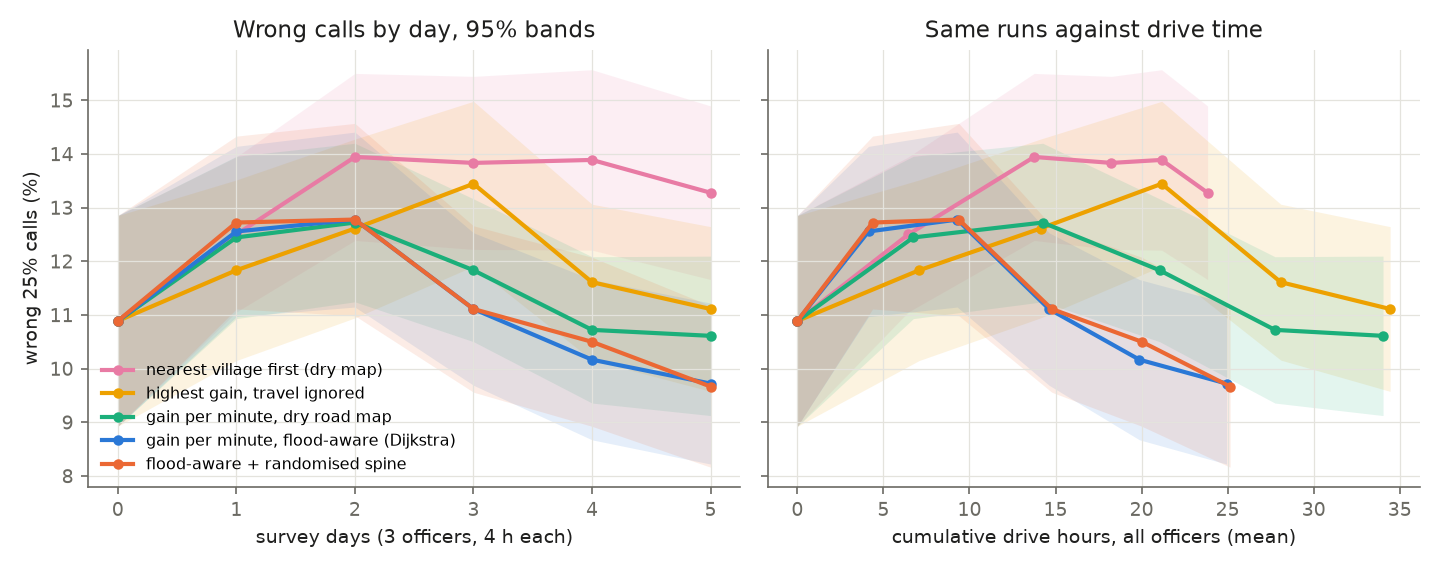

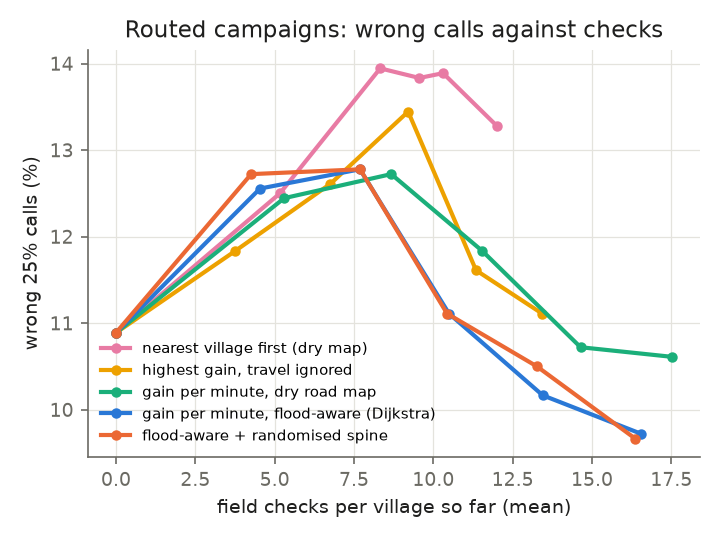

In [14]:
lab_r = dict(nearest="nearest village first (dry map)", gain_only="highest gain, travel ignored",
             gain_blind="gain per minute, dry road map", gain_aware="gain per minute, flood-aware (Dijkstra)",
             gain_aware_spine="flood-aware + randomised spine")
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for pl in R.PLANNERS:
    r = ev_route[pl]
    m, lo, hi = band(r["wrong"])
    axs[0].plot(range(DAYS + 1), 100 * m, marker="o", ms=4, color=COL[pl], label=lab_r[pl])
    axs[0].fill_between(range(DAYS + 1), 100 * lo, 100 * hi, color=COL[pl], alpha=0.12, lw=0)
    x = r["drive_min"].mean(0) / 60
    axs[1].plot(x, 100 * m, marker="o", ms=4, color=COL[pl])
    axs[1].fill_between(x, 100 * lo, 100 * hi, color=COL[pl], alpha=0.12, lw=0)
axs[0].set_xlabel(f"survey days ({K} officers, {T_DAY / 60:.0f} h each)"); axs[0].set_ylabel("wrong 25% calls (%)")
axs[0].set_title("Wrong calls by day, 95% bands", color=INK); axs[0].legend(fontsize=7.5)
axs[1].set_xlabel("cumulative drive hours, all officers (mean)")
axs[1].set_title("Same runs against drive time", color=INK)
fig.tight_layout(); fig.savefig(OUT / "fig_wrong_vs_drive.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "fig_wrong_vs_drive.png")))

fig, ax = plt.subplots(figsize=(4.8, 3.6))
for pl in R.PLANNERS:
    r = ev_route[pl]; m, lo, hi = band(r["wrong"]); x = r["checks"].mean(0) / U_ROUTE
    ax.plot(x, 100 * m, marker="o", ms=4, color=COL[pl], label=lab_r[pl])
ax.set_xlabel("field checks per village so far (mean)"); ax.set_ylabel("wrong 25% calls (%)")
ax.set_title("Routed campaigns: wrong calls against checks", color=INK); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig_route_wrong_vs_checks.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "fig_route_wrong_vs_checks.png")))

## 6b The same comparison on the layer-1 road network

The planners again, now on the real OpenStreetMap road graph of the study block (layer 1), with the
semi-synthetic flood layer from step 1 and 30 held-out truth draws (seeds not used anywhere else). The
block is small (most villages are under 20 minutes from the depot on dry roads), so this mainly checks
that the planner runs on a real, irregular graph and whether its advantage survives when travel binds
less.

In [15]:
REAL_SEEDS = list(range(3000, 3030))
ev_real = None
if region.get("source", "").startswith("layer1"):
    t0 = time.time()
    ev_real = {}
    for pl in R.PLANNERS:
        recs = [campaign(s, pl, P_CLOSE, priority=SPINE_PRIORITY, reg=region) for s in REAL_SEEDS]
        ev_real[pl] = {k: np.array([r[k] for r in recs], float) for k in ("wrong", "checks", "drive_min", "visits")}
    print(f"layer-1 road network, {len(REAL_SEEDS)} held-out truth draws ({time.time() - t0:.0f} s)")
    for pl in R.PLANNERS:
        r = ev_real[pl]
        print(f"{pl:17s}", " ".join(f"{100 * x:5.1f}" for x in r["wrong"].mean(0)),
              f"  visits {r['visits'][:, -1].mean():5.1f} drive-min {r['drive_min'][:, -1].mean():6.0f}")
    real_route_pair = {}
    for base in ("nearest", "gain_only", "gain_blind"):
        m, lo, hi = band(ev_real["gain_aware"]["wrong"][:, -1] - ev_real[base]["wrong"][:, -1])
        real_route_pair[f"gain_aware - {base}"] = dict(mean=float(m), lo=float(lo), hi=float(hi))
        print(f"day {DAYS}: gain_aware - {base:10s} {100 * m:+5.2f} points [{100 * lo:+.2f}, {100 * hi:+.2f}]")
else:
    print("layer 1 road network not present; skipped")

layer-1 road network, 30 held-out truth draws (40 s)
nearest            14.3  13.9  12.0  11.9  12.0  12.4   visits  34.7 drive-min   1268
gain_only          14.3  11.2  11.3  11.8  11.0  10.5   visits  41.7 drive-min   2154
gain_blind         14.3  13.3  12.1  11.6  11.0  11.0   visits  56.7 drive-min   2005
gain_aware         14.3  13.2  10.7   9.0   8.4   8.0   visits  74.6 drive-min   1733
gain_aware_spine   14.3  12.7  11.3   9.5   8.7   8.5   visits  75.0 drive-min   1695
day 5: gain_aware - nearest    -4.44 points [-6.39, -2.50]
day 5: gain_aware - gain_only  -2.50 points [-4.10, -0.90]
day 5: gain_aware - gain_blind -3.06 points [-4.77, -1.34]


## 7 Day-1 plan for the input region

The planner now runs once on the input region in its current state (layer 3's checks so far, or none):
inclusion probabilities, the spine draw, the next-check ranking, and the day-1 flood-aware routes for
the officers. This is what layer 5's day-route view shows. Flooded roads are drawn in blue (darker =
more likely flooded), segments closed by the planner are dashed, and the village shade is the value of
a visit.

In [16]:
rng_plan = np.random.default_rng(SEED)
Y_unknown = [np.zeros(len(p), bool) for p in region["P"]]       # outcomes are not known at planning time
S0 = A.StratSurvey(Y_unknown, region["f"], region["pi_h"], region["m"], region["tau"], rng_plan)
if region.get("n_done") is not None:                            # checks already made (from layer 3)
    S0.n, S0.k = region["n_done"].astype(float).copy(), region["k_done"].astype(float).copy()
g0, add0 = A.visit_gain(S0, C_VISIT)
wa = R.edge_costs(region, "aware", PLAN_SLOW, P_CLOSE)
Da, pred, sites = R.shortest(region, wa)
service = np.full(U0, C_VISIT * CHECK_MIN)
frame0 = (Da[0, 1:] + Da[1:, 0] + service) <= FRAME_MARGIN * T_DAY
q0 = np.zeros(U0)
q0[frame0] = Sel.pps_floor(R.spine_priority_values(S0, C_VISIT, SPINE_PRIORITY)[frame0], SPINE_N, SPINE_FLOOR)
spine0 = Sel.poisson_draw(q0, rng_plan)
print(f"spine frame: {frame0.sum()} of {U0} villages ({100 * S0.N[frame0].sum() / S0.N.sum():.0f}% of plots)")
routes0 = R.insertion(g0, Da, K, T_DAY, service, mandatory=spine0)
day1 = []
for r_i, rt in enumerate(routes0):
    seq = [0] + [v + 1 for v in rt] + [0]
    path = []
    for a, b in zip(seq[:-1], seq[1:]):
        seg = R.node_path(pred, sites, a, b)
        path += seg if not path else seg[1:]
    plan_min = float(sum(Da[a, b] for a, b in zip(seq[:-1], seq[1:])) + service[rt].sum())
    day1.append(dict(officer=r_i + 1, units=[region["unit_id"][v] for v in rt], unit_index=[int(v) for v in rt],
                     node_path=[int(n) for n in path], planned_minutes=round(plan_min, 1),
                     expected_gain=float(g0[rt].sum())))
    print(f"officer {r_i + 1}: {len(rt)} villages, planned {plan_min:.0f} of {T_DAY:.0f} min, expected drop in wrong calls {g0[rt].sum():.3f}")
print("spine villages drawn:", [region["unit_id"][v] for v in spine0])
print("expected wrong calls now:", round(float(A.p_wrong(S0.estimate()[0] - S0.tau, S0.estimate()[1]).sum()), 2), "of", U0)

spine frame: 22 of 36 villages (61% of plots)
officer 1: 8 villages, planned 234 of 240 min, expected drop in wrong calls 2.456
officer 2: 7 villages, planned 210 of 240 min, expected drop in wrong calls 2.094
officer 3: 5 villages, planned 233 of 240 min, expected drop in wrong calls 1.264
spine villages drawn: ['G0000', 'G0001', 'G0102', 'G0103', 'G0202', 'G0300']
expected wrong calls now: 13.72 of 36


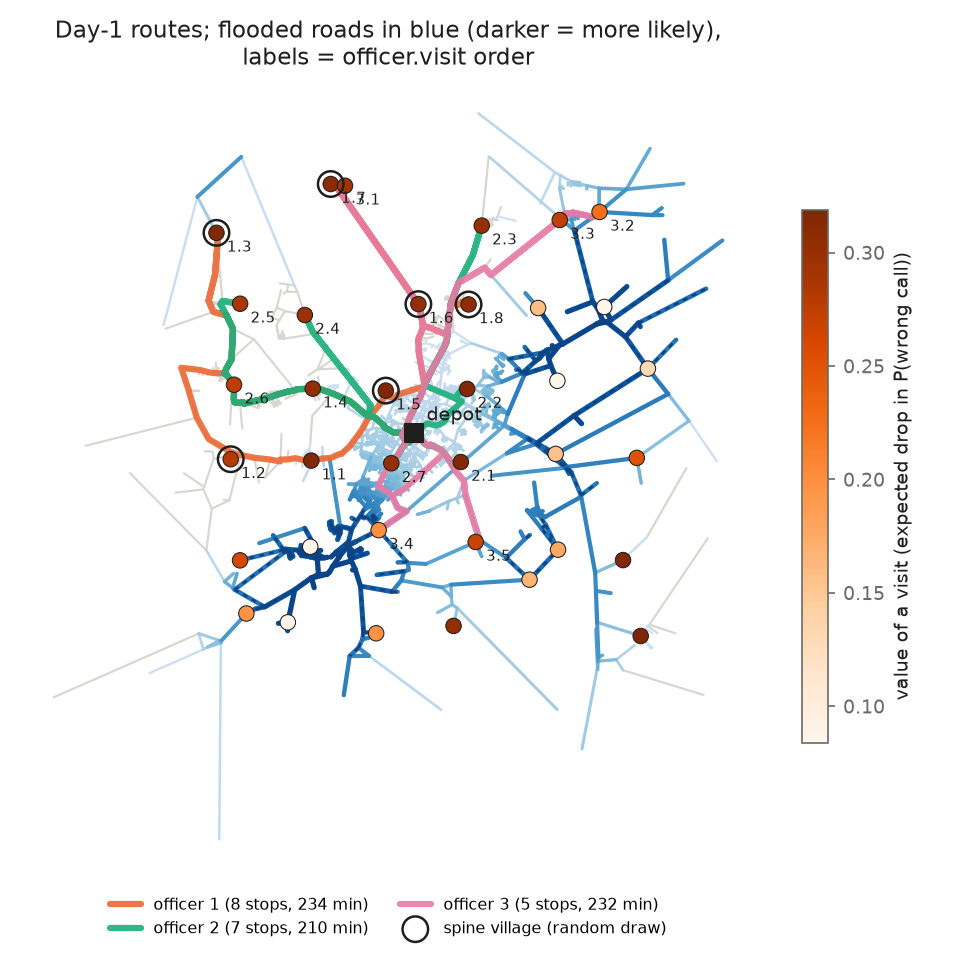

In [17]:
fig, ax = plt.subplots(figsize=(6.4, 6.4))
xy = region["xy"]
draw_roads(ax, region)
if P_CLOSE is not None:
    for (a, b) in region["edges"][region["p_edge"] >= P_CLOSE]:
        ax.plot(xy[[a, b], 0], xy[[a, b], 1], color="#104281", lw=1.2, ls=(0, (2, 2)), zorder=1.5)
off_col = ["#eb6834", "#1baf7a", "#e87ba4", "#eda100", "#008300"]
for d in day1:
    p = np.array(d["node_path"])
    if len(p) > 1:
        ax.plot(xy[p, 0], xy[p, 1], color=off_col[(d["officer"] - 1) % len(off_col)], lw=3, alpha=0.9, zorder=2,
                solid_capstyle="round", label=f"officer {d['officer']} ({len(d['units'])} stops, {d['planned_minutes']:.0f} min)")
        for j, v in enumerate(d["unit_index"]):
            ax.annotate(f"{d['officer']}.{j + 1}", xy[region["unit_node"][v]], xytext=(5, -9), textcoords="offset points",
                        color=INK, fontsize=7, zorder=5)
sc = ax.scatter(uxy[:, 0], uxy[:, 1], c=g0, cmap="Oranges", s=55, edgecolor=INK, lw=0.5, zorder=3)
ax.scatter(uxy[spine0, 0], uxy[spine0, 1], s=150, facecolor="none", edgecolor=INK, lw=1.2, zorder=4, label="spine village (random draw)")
ax.scatter(*xy[region["depot"]], marker="s", c=INK, s=70, zorder=4)
ax.annotate("depot", xy[region["depot"]], xytext=(6, 6), textcoords="offset points", color=INK)
fig.colorbar(sc, ax=ax, shrink=0.6, label="value of a visit (expected drop in P(wrong call))")
ax.set_title("Day-1 routes; flooded roads in blue (darker = more likely),\nlabels = officer.visit order", color=INK)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2)
ax.set_aspect("equal"); ax.axis("off")
fig.tight_layout(); fig.savefig(OUT / "route_day1.png", dpi=150); plt.close(fig)
display(Image(str(OUT / "route_day1.png")))

## 8 Artifacts

Written to `artifacts/layer4/`:
* `routes_day1.json`: per officer the villages in visit order, the road-node path, planned minutes;
* `checks_day1.json`: per village and stratum the planned checks and the inclusion probability of each
  checked plot (q_v * c_vh / N_vh for spine villages; adaptive checks carry `inclusion_prob: null`
  and must not enter a design-weighted pooled estimate);
* `inclusion_probs.json`: q_v for every village and the spine draw;
* `next_checks.json`: ranked next checks by the decision rule (for layer 5 when there is no travel limit);
* `eval_allocation.json` (synthetic), `eval_allocation_real_chips.json` (labelled test chips),
  `eval_routing.json` (synthetic), `eval_routing_real_roads.json` (layer-1 roads), `eval_bias.json`,
  `tuning.json`; figures `*.png` (`route_day1.png` is the day-route view for layer 5);
* `MANIFEST.json`: schema, shapes, seeds, hashes of the inputs and of the code.

In [18]:
def sha(p):
    return hashlib.sha256(pathlib.Path(p).read_bytes()).hexdigest()[:16]

def dump(name, obj):
    (OUT / name).write_text(json.dumps(obj, indent=1, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o)))

spine_set = set(int(v) for v in spine0)
checks = []
for v in range(U0):
    if v in spine_set:
        c = Sel.design_split(S0.Nh[v] - S0.n[v], C_VISIT); kind = "design"
    else:
        c = add0[v].astype(int); kind = "adaptive"
    in_route = any(v in d["unit_index"] for d in day1)
    for h in (0, 1):
        checks.append(dict(unit=region["unit_id"][v], unit_index=v, stratum=("mapped_dry", "mapped_flooded")[h],
                           N_stratum=int(S0.Nh[v, h]), planned_checks=int(c[h]) if in_route else 0, kind=kind,
                           village_inclusion_prob=float(q0[v]), in_day1_route=bool(in_route),
                           inclusion_prob=(float(q0[v] * c[h] / S0.Nh[v, h]) if kind == "design" and S0.Nh[v, h] > 0 else None)))
dump("routes_day1.json", dict(officers=K, day_minutes=T_DAY, check_minutes=CHECK_MIN, checks_per_visit=C_VISIT,
                              p_close=P_CLOSE, plan_slow=PLAN_SLOW, true_slow_factor=SLOW, routes=day1))
dump("checks_day1.json", checks)
dump("inclusion_probs.json", dict(method="Poisson sampling over the frame, q_v = clip(c * priority_v, floor, 1), sum q = n_expected; q_v = 0 outside the frame",
                                  priority=SPINE_PRIORITY, frame_margin=FRAME_MARGIN, n_expected=SPINE_N, floor=SPINE_FLOOR, seed=SEED,
                                  units=[dict(unit=region["unit_id"][v], q=float(q0[v]), in_frame=bool(frame0[v]), visit_gain=float(g0[v]),
                                              drawn=bool(v in spine_set)) for v in range(U0)]))
dump("next_checks.json", [dict(r, unit=region["unit_id"][r["unit"]]) for r in A.next_checks(S0, 30)])
dump("eval_allocation.json", dict(budgets_per_village=BUDGETS, villages=U_ALLOC, eval_seeds=EVAL_REGIONS, settings=best_alloc,
                                  wrong={r: dict(zip(("mean", "lo", "hi"), [x.tolist() for x in band(v["wrong"])])) for r, v in ev_alloc.items()},
                                  brier={r: band(v["brier"])[0].tolist() for r, v in ev_alloc.items()}, paired_decision_minus=pair_alloc))
dump("eval_routing.json", dict(villages=U_ROUTE, officers=K, days=DAYS, day_minutes=T_DAY, p_close=P_CLOSE, eval_seeds=EVAL_REGIONS,
                               planners={pl: dict(wrong=dict(zip(("mean", "lo", "hi"), [x.tolist() for x in band(r["wrong"])])),
                                                  brier=band(r["brier"])[0].tolist(), checks=r["checks"].mean(0).tolist(),
                                                  drive_min=r["drive_min"].mean(0).tolist(), visits=r["visits"].mean(0).tolist())
                                         for pl, r in ev_route.items()},
                               paired_day_last=pair_route,
                               plan_slow=PLAN_SLOW, spine_priority=SPINE_PRIORITY, travel_time_rel_error=te))
if real_alloc is not None:
    dump("eval_allocation_real_chips.json", dict(split="test", budgets_per_unit=CHIP_BUDGETS, units=Uc, pi_h_train=pi_chip,
                                                 wrong={r: dict(zip(("mean", "lo", "hi"), [x.tolist() for x in band(v)])) for r, v in real_alloc.items()},
                                                 paired_decision_minus=real_pair, mc_seeds=EVAL_REGIONS))
if ev_real is not None:
    dump("eval_routing_real_roads.json", dict(seeds=REAL_SEEDS, planners={pl: dict(wrong=r["wrong"].mean(0).tolist(), drive_min=r["drive_min"].mean(0).tolist(),
                                                                                  visits=r["visits"].mean(0).tolist()) for pl, r in ev_real.items()},
                                              paired_day_last=real_route_pair))
dump("eval_bias.json", dict(seeds=BIAS_REGIONS, target="frame villages", priority=SPINE_PRIORITY,
                            coverage=float(np.mean([b["coverage"] for b in bt])), drawn=float(np.mean([b["drawn"] for b in bt])), reached=float(np.mean([b["got"] for b in bt])), spine_expected=SPINE_N, floor=SPINE_FLOOR, table=bias_tab))
dump("tuning.json", dict(tune_seeds=TUNE_REGIONS, allocation=tune_alloc, chosen_allocation=best_alloc,
                         p_close=tune_close, chosen_p_close=P_CLOSE,
                         plan_slow_mean_abs_rel_error={str(k): v for k, v in tune_slow.items()}, chosen_plan_slow=PLAN_SLOW,
                         spine_priority_rmse=tune_prio, chosen_spine_priority=SPINE_PRIORITY))

inputs = {}
for L in ("layer1", "layer2", "layer3"):
    for p in sorted((ART / L).glob("*")) if (ART / L).exists() else []:
        if p.is_file():
            inputs[f"{L}/{p.name}"] = sha(p)
code = {f"paddybird/{n}": sha(ROOT / "paddybird" / n) for n in ("allocation.py", "routing.py", "selection.py")}
files = {}
for p in sorted(OUT.glob("*")):
    if p.name != "MANIFEST.json":
        files[p.name] = dict(sha256_16=sha(p), bytes=p.stat().st_size)
manifest = dict(layer=4, notebook="04_field_planning.ipynb", input_source=INPUT_SOURCE, seed=SEED,
                seeds=dict(tune=[TUNE_REGIONS[0], TUNE_REGIONS[-1]], eval=[EVAL_REGIONS[0], EVAL_REGIONS[-1]],
                           bias=[BIAS_REGIONS[0], BIAS_REGIONS[-1]], truth_offset=TRUTH_OFFSET),
                region=dict(units=U0, road_nodes=int(len(region["xy"])), road_segments=int(len(region["edges"])),
                            tau=float(region["tau"]), m=float(region["m"]), pi_h=np.round(region["pi_h"], 4).tolist()),
                schema={
                    "routes_day1.json": "{officers, day_minutes, ..., routes: [{officer, units[str], unit_index[int], node_path[int], planned_minutes, expected_gain}]}",
                    "checks_day1.json": "[{unit, unit_index, stratum, N_stratum, planned_checks, kind: design|adaptive, village_inclusion_prob, in_day1_route, inclusion_prob|null}]",
                    "inclusion_probs.json": "{method, priority, frame_margin, n_expected, floor, seed, units: [{unit, q, in_frame, visit_gain, drawn}]}",
                    "next_checks.json": "[{rank, unit, stratum, gain}]",
                    "eval_*.json": "held-out Monte Carlo summaries (mean, 95% band lo/hi)",
                    "tuning.json": "settings tried on tuning seeds only"},
                shapes=dict(checks_day1=len(checks), routes=len(day1), units=U0),
                versions=dict(python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__),
                inputs_sha256_16=inputs, code_sha256_16=code, files=files)
(OUT / "MANIFEST.json").write_text(json.dumps(manifest, indent=1))
print("wrote", len(files) + 1, "files to", OUT.relative_to(ROOT))

wrote 18 files to artifacts\layer4


## 9 Checks

Bounds stated in advance (held-out scenarios):
1. the decision rule is not worse than uncertainty-only at 16 or more checks per village (paired 95% upper bound below +1 point);
2. at 32 checks per village the decision rule beats the map alone;
3. flood-aware gain-per-minute routing is not worse than nearest-first after the last day (paired upper bound below +1 point);
4. the Hajek spine estimate of both pi_h and the district share has a 95% CI that contains 0 or a bias below 1 point;
5. the artifacts and manifest exist.

In [19]:
p = pair_alloc["uncertainty"]
assert all(p["hi"][i] < 0.01 for i, b in enumerate(BUDGETS) if b >= 16), p["hi"]
assert ev_alloc["decision"]["wrong"][:, -1].mean() < ev_alloc["decision"]["wrong"][:, 0].mean()
assert pair_route["gain_aware - nearest"]["hi"] < 0.01, pair_route["gain_aware - nearest"]
for t in ("pi_dry", "pi_flooded", "district_share"):
    v = bias_tab[f"hajek|{t}"]
    assert (v["lo"] <= 0 <= v["hi"]) or abs(v["bias"]) < 0.01, (t, v)
for f in ("MANIFEST.json", "routes_day1.json", "checks_day1.json", "inclusion_probs.json", "route_day1.png"):
    assert (OUT / f).exists(), f
print("all layer 4 checks passed")

all layer 4 checks passed


## 10 Findings (read with the numbers printed above)

Numbers quoted here are from the run that produced the committed artifacts (layer 3 prior strength
m = 1, tau = 0.25). If layer 3 is re-run with other settings the printed tables above are the
authority; the wording below is what to re-check.

**Where planning helps**
* **Allocation, synthetic (60 held-out scenarios, 80 villages).** The decision rule makes fewer wrong
  calls than random, proportional and uncertainty-only allocation at every budget from 2 to 32 checks
  per village. At 16 checks it is 8.6% wrong against 12.6% (uncertainty-only), 13.8% (proportional)
  and 14.0% (random), with paired 95% intervals well below zero. It reaches the baselines' 32-check
  level (about 10%) with about 12 checks.
* **Allocation, real map error (91 labelled test pseudo-villages, events held out).** The decision rule
  is best or tied from 2 to 16 checks per unit (at 8 checks 4.1% against 4.9% uncertainty-only and 6.2
  to 6.6% for proportional and random).
* **Routing.** Gain per minute on the flood-aware graph beats nearest-first by about 3.6 points after 5
  days on synthetic regions and 4.4 points on the layer-1 road network, and beats "highest gain, travel
  ignored" by 1.4 and 2.5 points. On the layer-1 roads it also beats the same planner on the dry road
  map by 3.1 points [1.3, 4.8].
* **Selection.** With the randomised spine (villages drawn with probability proportional to size,
  floor 0.05, inside a reachable frame) the Hajek estimates of pi_h and of the frame's flooded share
  show no detectable bias (all within 0.3 points, 95% intervals contain 0), whereas pooling all routed
  checks over-states P(flooded | mapped dry) by 1.5 points [1.1, 2.0] and the calibration prior alone
  is off by up to 4.1 points. The spine costs no measurable accuracy in the village calls (paired gap
  on day 5: -0.06 points [-0.60, +0.49]).

**Where planning does not beat simple baselines (reported as is)**
* **Few checks are worse than no checks.** With layer 3's weak prior (m = 1), 2 to 4 checks per village
  make more wrong calls than the map alone for every rule on the synthetic regions (map 11.4%; decision
  rule 19.2% at 2 checks, 14.7% at 4). The decision rule only matches the map at about 8 checks and
  beats it from 12. In the routed campaigns every planner is worse than the map alone on days 1 to 3,
  and only the flood-aware planners end below it on day 5 (9.7% against 10.9%). This is the effect the
  report saw at 2 to 4 checks; it argues for a stronger prior in layer 3, or for keeping the map call
  until a village has enough checks.
* **At high budgets on real error the decision rule loses its edge.** At 32 checks per unit on the
  labelled test chips it is 3.6% wrong against 3.1% for uncertainty-only (paired +0.5 points [+0.1,
  +0.9]) and level with random and proportional. Once most units are settled, spending on the variance
  of the rest is as good or better.
* **Flood-aware against flood-blind gain routing on the synthetic lattice is not significant**
  (-0.9 points [-1.9, +0.1]); there the flood-aware plan does the same work with about 27% less driving
  (1,496 against 2,042 minutes), which is its clearer benefit.
* **The obvious flood-aware cost is worse than the dry map.** Pricing each segment at its expected time
  with the true 8x slow-down over-states travel by about 50%, because on the day the officer takes
  whichever roads are dry. The slow-down assumed by the planner had to be fitted on tuning seeds (4x,
  mean error 21% against 30% for the dry map).
* **Routing bias in this simulated world is small.** The gain-aware routes reach most of the frame
  within 5 days, so naive pooling is biased only for the mapped-dry rate, and it has a lower root-mean-
  square error than the unbiased spine estimate (0.030 against 0.049) because it uses about ten times
  more checks. The spine buys a guarantee (no bias whatever the routes do), not a smaller error here.
  Horvitz-Thompson is unbiased but much noisier (0.20 for mapped flooded). A gain-proportional spine,
  as in the report, gave a biased Hajek estimate in development (about -4 points for mapped flooded)
  because of uneven weights, which is why the priority was tuned and size won.
* **Coverage.** The frame (villages whose expected round trip plus checks fits in 60% of a day) covers
  about half of the plots in the synthetic regions, and in about a quarter of them no village was in
  the frame at all (depot inside the flood). Design estimates say nothing about villages outside it.

**Limits.** Plots inside a village are independent in the synthetic world (layer 3 shows that real
checks cluster); the flood layer over the study block is semi-synthetic because layer 2 has no map
there; the routing truth (a flooded segment takes 8 times its dry time, independently per segment) is
an assumption; the labelled-chip check uses water labels, not flooded paddy.